# CatBoost baseline на mesh

## 1. Библиотеки

In [1]:
%pip install -q catboost iterative-stratification


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from catboost import CatBoostClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score

DATA_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data' / 'train.csv').is_file())
ROOT = DATA_ROOT / 'archive'
TRAIN_DIR = DATA_ROOT / 'data' / 'train'

SEED = 42
np.random.seed(SEED)


c:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Данные

In [3]:
train = pd.read_csv(DATA_ROOT / 'data' / 'train.csv')
target_columns = train.columns.drop('item_id').tolist()

print(train.shape)
print(target_columns)


(8964, 12)
['abstract', 'artifacts', 'intersection', 'lowpoly', 'noisy', 'open', 'partial', 'scale', 'set', 'simple', 'quality']


## 3. Mesh-признаки

In [4]:
def extract_mesh_features(item_id):
    with np.load(TRAIN_DIR / f'{item_id}.npz') as mesh:
        vertices = mesh['vertices'].astype(np.float32)
        faces = mesh['faces'].astype(np.int64)

    minimum = vertices.min(axis=0)
    maximum = vertices.max(axis=0)
    sizes = maximum - minimum

    center = vertices.mean(axis=0)
    radius = np.linalg.norm(vertices - center, axis=1)
    coordinate_std = vertices.std(axis=0)

    sorted_sizes = np.sort(sizes)

    features = {
        'vertices_count': len(vertices),
        'faces_count': len(faces),
        'faces_per_vertex': len(faces) / max(len(vertices), 1),
        'size_x': sizes[0],
        'size_y': sizes[1],
        'size_z': sizes[2],
        'size_min': sorted_sizes[0],
        'size_middle': sorted_sizes[1],
        'size_max': sorted_sizes[2],
        'min_to_max': sorted_sizes[0] / (sorted_sizes[2] + 1e-8),
        'middle_to_max': sorted_sizes[1] / (sorted_sizes[2] + 1e-8),
        'bbox_volume': np.prod(sizes),
        'bbox_diagonal': np.linalg.norm(sizes),
        'std_x': coordinate_std[0],
        'std_y': coordinate_std[1],
        'std_z': coordinate_std[2],
        'radius_mean': radius.mean(),
        'radius_std': radius.std(),
        'radius_max': radius.max()
    }

    if len(faces) > 0:
        sample_size = min(len(faces), 5000)
        face_indices = np.linspace(
            0,
            len(faces) - 1,
            sample_size,
            dtype=int
        )
        triangles = vertices[faces[face_indices]]

        edge_1 = np.linalg.norm(triangles[:, 1] - triangles[:, 0], axis=1)
        edge_2 = np.linalg.norm(triangles[:, 2] - triangles[:, 1], axis=1)
        edge_3 = np.linalg.norm(triangles[:, 0] - triangles[:, 2], axis=1)
        edges = np.concatenate([edge_1, edge_2, edge_3])

        areas = np.linalg.norm(
            np.cross(
                triangles[:, 1] - triangles[:, 0],
                triangles[:, 2] - triangles[:, 0]
            ),
            axis=1
        ) / 2

        features.update({
            'edge_mean': edges.mean(),
            'edge_std': edges.std(),
            'edge_max': edges.max(),
            'face_area_mean': areas.mean(),
            'face_area_std': areas.std(),
            'face_area_max': areas.max(),
            'surface_area': areas.mean() * len(faces),
            'degenerate_faces_ratio': (areas < 1e-10).mean()
        })
    else:
        features.update({
            'edge_mean': 0,
            'edge_std': 0,
            'edge_max': 0,
            'face_area_mean': 0,
            'face_area_std': 0,
            'face_area_max': 0,
            'surface_area': 0,
            'degenerate_faces_ratio': 0
        })

    return features


In [5]:
ARTIFACTS_DIR = ROOT / 'artifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_PATH = ARTIFACTS_DIR / 'train_mesh_features.csv'

if FEATURES_PATH.exists():
    mesh_features = pd.read_csv(FEATURES_PATH)
    print('Загружены готовые признаки')
else:
    rows = []

    for item_id in tqdm(train['item_id']):
        row = {'item_id': item_id}
        row.update(extract_mesh_features(item_id))
        rows.append(row)

    mesh_features = pd.DataFrame(rows)
    mesh_features.to_csv(FEATURES_PATH, index=False)
    print('Признаки сохранены:', FEATURES_PATH)

mesh_features.head()


100%|██████████| 8964/8964 [26:52<00:00,  5.56it/s]  


Признаки сохранены: artifacts\train_mesh_features.csv


,item_id,vertices_count,faces_count,faces_per_vertex,size_x,size_y,size_z,size_min,size_middle,size_max,...,radius_std,radius_max,edge_mean,edge_std,edge_max,face_area_mean,face_area_std,face_area_max,surface_area,degenerate_faces_ratio
0,0001be62-bf9c-4c15-8a09-dce209be9715,22447,41932,1.868045,0.701962,0.873576,1.000000,0.701962,0.873576,1.0,...,0.122573,0.779267,0.015589,0.035475,0.520134,0.000127,0.000645,0.031434,5.327299,0.0000
1,000ad3b9-75cf-4b8f-9786-de63f9a8ffa8,7414,14800,1.996223,190.000000,85.000000,2.000000,2.000000,85.000000,190.0,...,22.205286,108.995819,3.168518,8.052528,190.010529,1.829801,9.253392,317.571075,27081.048828,0.0000
2,0012e069-5caf-44fd-85e4-9a38f6eefd2e,5437,11214,2.062534,190.301407,199.000000,1.800000,1.800000,190.301407,199.0,...,23.563826,124.774025,3.543089,4.835792,35.825115,4.385052,13.834538,354.623779,49173.968750,0.0000
3,0024dc8f-a2d7-4556-94dc-6b4b0f46ca0d,2994,5972,1.994656,1.000000,0.310122,0.853376,0.310122,0.853376,1.0,...,0.112557,1.012542,0.014075,0.032489,0.492072,0.000096,0.000892,0.050492,0.575610,0.0018
4,002b097b-4237-4610-952c-6095d48fb7a0,8033,16202,2.016930,149.000000,71.000000,43.361000,43.361000,71.000000,149.0,...,7.486299,83.557663,1.540442,5.248391,149.883286,2.093478,72.431000,4686.000000,33918.527344,0.0046


In [6]:
assert mesh_features['item_id'].is_unique
assert set(mesh_features['item_id']) == set(train['item_id']), 'Mesh feature cache is incomplete'

data = train.merge(
    mesh_features,
    on='item_id',
    how='inner',
    validate='one_to_one'
)

feature_columns = [
    column
    for column in mesh_features.columns
    if column != 'item_id'
]

data[feature_columns] = (
    data[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print('Объектов:', len(data))
print('Признаков:', len(feature_columns))


Объектов: 8964
Признаков: 27


## 4. Разделение данных

In [7]:
splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_index, test_index = next(
    splitter.split(data, data[target_columns])
)

train_val_df = data.iloc[train_val_index].reset_index(drop=True)
test_df = data.iloc[test_index].reset_index(drop=True)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=43
)

train_index, val_index = next(
    splitter.split(
        train_val_df,
        train_val_df[target_columns]
    )
)

train_df = train_val_df.iloc[train_index].reset_index(drop=True)
val_df = train_val_df.iloc[val_index].reset_index(drop=True)

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Internal test:', len(test_df))


Train: 6259
Validation: 1361
Internal test: 1344


## 5. Обучение

In [8]:
X_train = train_df[feature_columns]
X_val = val_df[feature_columns]

val_probabilities = np.zeros(
    (len(val_df), len(target_columns))
)

models = {}
MODELS_DIR = ROOT / 'models' / 'catboost'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for column_index, target in enumerate(target_columns):
    model = CatBoostClassifier(
        iterations=400,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        auto_class_weights='Balanced',
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        train_df[target],
        eval_set=(X_val, val_df[target]),
        early_stopping_rounds=50,
        verbose=False
    )

    val_probabilities[:, column_index] = model.predict_proba(X_val)[:, 1]
    model.save_model(str(MODELS_DIR / f'{target}.cbm'))
    models[target] = model

    print(target, '- trees:', model.tree_count_)


abstract - trees: 147
artifacts - trees: 38
intersection - trees: 5
lowpoly - trees: 193
noisy - trees: 207
open - trees: 49
partial - trees: 59
scale - trees: 13
set - trees: 179
simple - trees: 206
quality - trees: 248


## 6. Метрики

In [9]:
def calculate_metrics(targets, probabilities, thresholds):
    predictions = (probabilities >= thresholds).astype(int)
    defect_indices = [i for i, name in enumerate(target_columns) if name != 'quality']

    class_f1 = f1_score(
        targets,
        predictions,
        average=None,
        zero_division=0
    )
    weighted_f1 = f1_score(
        targets[:, defect_indices],
        predictions[:, defect_indices],
        average='weighted',
        zero_division=0
    )
    quality_f1 = class_f1[target_columns.index('quality')]

    return class_f1, weighted_f1, quality_f1, (
        weighted_f1 + quality_f1
    ) / 2


In [10]:
val_targets = val_df[target_columns].to_numpy()

class_f1, weighted_f1, quality_f1, score = calculate_metrics(
    val_targets,
    val_probabilities,
    thresholds=0.5
)

display(pd.DataFrame({
    'target': target_columns,
    'F1': class_f1
}).round(4))

print('Macro F1:', round(class_f1.mean(), 4))
print('Weighted F1 дефектов:', round(weighted_f1, 4))
print('F1 quality:', round(quality_f1, 4))
print('Score:', round(score, 4))


,target,F1
0,abstract,0.5342
1,artifacts,0.1561
2,intersection,0.0466
3,lowpoly,0.4773
4,noisy,0.7543
5,open,0.1890
6,partial,0.2662
7,scale,0.0833
8,set,0.3216
9,simple,0.6771


Macro F1: 0.3642
Weighted F1 дефектов: 0.5364
F1 quality: 0.5009
Score: 0.5186


## 7. Анализ baseline

In [11]:
from sklearn.metrics import precision_score, recall_score

baseline_predictions = (val_probabilities >= 0.5).astype(int)

error_table = pd.DataFrame({
    'target': target_columns,
    'positive': val_targets.sum(axis=0).astype(int),
    'precision': precision_score(
        val_targets,
        baseline_predictions,
        average=None,
        zero_division=0
    ),
    'recall': recall_score(
        val_targets,
        baseline_predictions,
        average=None,
        zero_division=0
    ),
    'F1': class_f1
})

error_table.sort_values('F1').round(4)


,target,positive,precision,recall,F1
2,intersection,16,0.0242,0.6250,0.0466
7,scale,16,0.0455,0.5000,0.0833
1,artifacts,65,0.0875,0.7231,0.1561
5,open,82,0.1153,0.5244,0.1890
6,partial,56,0.1646,0.6964,0.2662
8,set,141,0.2267,0.5532,0.3216
3,lowpoly,166,0.3548,0.7289,0.4773
10,quality,206,0.3887,0.7039,0.5009
0,abstract,179,0.4243,0.7207,0.5342
9,simple,289,0.5731,0.8270,0.6771


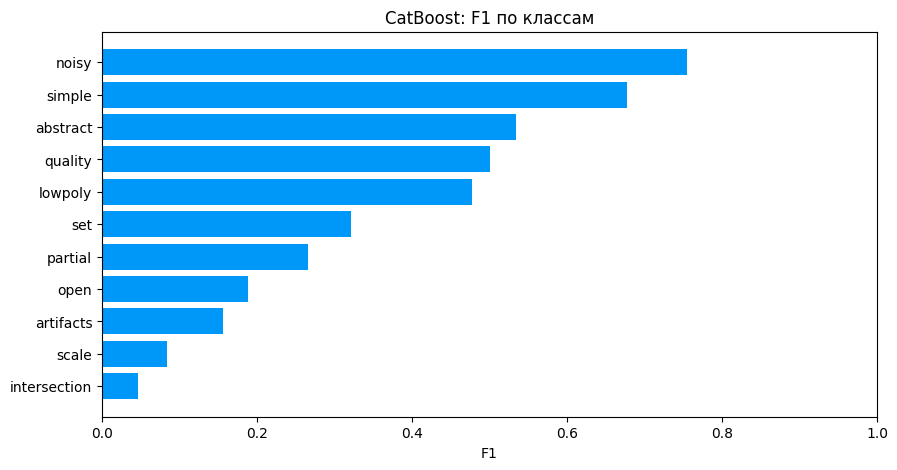

In [12]:
plot_data = error_table.sort_values('F1')

plt.figure(figsize=(10, 5))
plt.barh(plot_data['target'], plot_data['F1'], color='#0098F8')
plt.xlabel('F1')
plt.title('CatBoost: F1 по классам')
plt.xlim(0, 1)
plt.show()


,importance
min_to_max,15.4305
faces_per_vertex,6.9512
surface_area,6.4540
edge_std,5.9284
faces_count,4.4642
edge_max,4.0319
radius_max,3.9077
std_z,3.8824
radius_mean,3.6301
face_area_std,3.5843


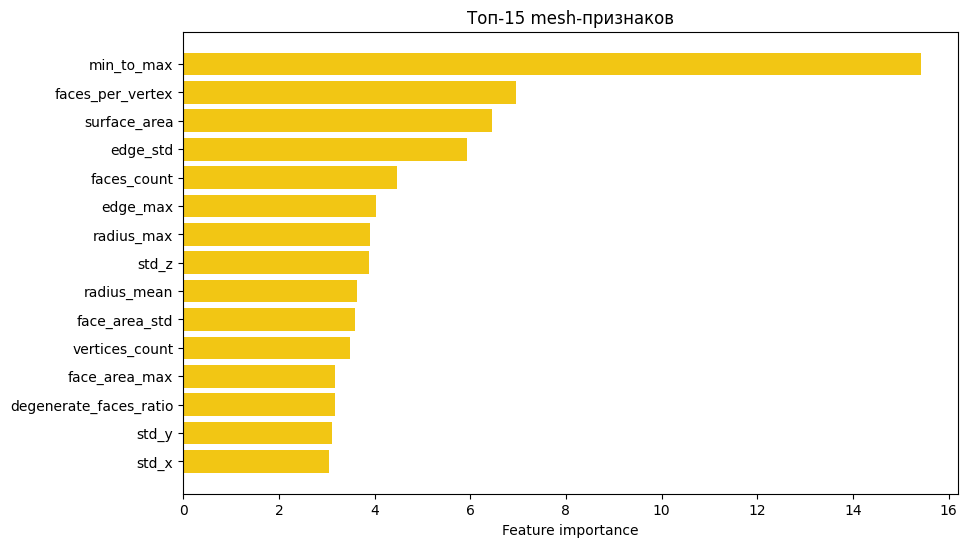

In [13]:
feature_importance = pd.DataFrame({
    target: models[target].get_feature_importance()
    for target in target_columns
}, index=feature_columns)

mean_importance = (
    feature_importance
    .mean(axis=1)
    .sort_values(ascending=False)
    .head(15)
)

display(mean_importance.to_frame('importance').round(4))

plt.figure(figsize=(10, 6))
plt.barh(
    mean_importance.sort_values().index,
    mean_importance.sort_values().values,
    color='#F2C614'
)
plt.xlabel('Feature importance')
plt.title('Топ-15 mesh-признаков')
plt.show()


## 8. Threshold tuning

In [14]:
threshold_grid = np.arange(0.05, 0.96, 0.01)
best_thresholds = []

for column_index in range(len(target_columns)):
    target = val_targets[:, column_index]
    probabilities = val_probabilities[:, column_index]

    scores = [
        f1_score(
            target,
            probabilities >= threshold,
            zero_division=0
        )
        for threshold in threshold_grid
    ]

    best_thresholds.append(
        threshold_grid[np.argmax(scores)]
    )

best_thresholds = np.array(best_thresholds)

pd.DataFrame({
    'target': target_columns,
    'threshold': best_thresholds
}).round(2)


,target,threshold
0,abstract,0.61
1,artifacts,0.62
2,intersection,0.56
3,lowpoly,0.66
4,noisy,0.53
5,open,0.55
6,partial,0.73
7,scale,0.66
8,set,0.59
9,simple,0.53


In [15]:
tuned_class_f1, tuned_weighted_f1, tuned_quality_f1, tuned_score = (
    calculate_metrics(
        val_targets,
        val_probabilities,
        thresholds=best_thresholds
    )
)

pd.DataFrame({
    'variant': ['threshold 0.5', 'tuned thresholds'],
    'macro_f1': [class_f1.mean(), tuned_class_f1.mean()],
    'weighted_f1': [weighted_f1, tuned_weighted_f1],
    'quality_f1': [quality_f1, tuned_quality_f1],
    'score': [score, tuned_score]
}).round(4)


,variant,macro_f1,weighted_f1,quality_f1,score
0,threshold 0.5,0.3642,0.5364,0.5009,0.5186
1,tuned thresholds,0.4059,0.5614,0.5108,0.5361


In [16]:
THRESHOLDS_PATH = ARTIFACTS_DIR / 'catboost_mesh_thresholds.json'

thresholds_to_save = {
    target: float(threshold)
    for target, threshold in zip(target_columns, best_thresholds)
}

with open(THRESHOLDS_PATH, 'w', encoding='utf-8') as file:
    json.dump(thresholds_to_save, file, indent=2)

print('Сохранено:', THRESHOLDS_PATH)


Сохранено: artifacts\catboost_mesh_thresholds.json


## 9. Подбор параметров CatBoost

In [17]:
experiments = {
    'depth_5': {'depth': 5, 'l2_leaf_reg': 3},
    'depth_7': {'depth': 7, 'l2_leaf_reg': 10},
    'leaves_31': {
        'grow_policy': 'Lossguide',
        'depth': 8,
        'max_leaves': 31,
        'min_data_in_leaf': 20,
        'l2_leaf_reg': 5
    }
}

TUNED_MODELS_DIR = ROOT / 'models' / 'catboost_tuned'
TUNED_MODELS_DIR.mkdir(parents=True, exist_ok=True)


def tune_thresholds(probabilities):
    thresholds = []
    for index in range(len(target_columns)):
        scores = [
            f1_score(
                val_targets[:, index],
                probabilities[:, index] >= threshold,
                zero_division=0
            )
            for threshold in threshold_grid
        ]
        thresholds.append(threshold_grid[np.argmax(scores)])
    return np.array(thresholds)


In [18]:
best_name = 'baseline'
best_models = models.copy()
best_probabilities = val_probabilities.copy()
best_thresholds = tune_thresholds(best_probabilities)
best_score = calculate_metrics(
    val_targets, best_probabilities, best_thresholds
)[3]

experiment_rows = [{
    'variant': best_name,
    'score_0.5': score,
    'score_tuned': best_score
}]

for name, parameters in experiments.items():
    candidate_models = {}
    probabilities = np.zeros_like(val_probabilities)

    for index, target in enumerate(target_columns):
        model = CatBoostClassifier(
            **parameters,
            iterations=600,
            learning_rate=0.04,
            loss_function='Logloss',
            auto_class_weights='Balanced',
            random_seed=SEED,
            verbose=False,
            allow_writing_files=False
        )
        model.fit(
            X_train, train_df[target],
            eval_set=(X_val, val_df[target]),
            early_stopping_rounds=50,
            verbose=False
        )
        candidate_models[target] = model
        probabilities[:, index] = model.predict_proba(X_val)[:, 1]

    thresholds = tune_thresholds(probabilities)
    candidate_score = calculate_metrics(
        val_targets, probabilities, thresholds
    )[3]
    experiment_rows.append({
        'variant': name,
        'score_0.5': calculate_metrics(val_targets, probabilities, 0.5)[3],
        'score_tuned': candidate_score
    })
    print(name, round(candidate_score, 4))

    if candidate_score > best_score:
        best_name = name
        best_models = candidate_models
        best_probabilities = probabilities
        best_thresholds = thresholds
        best_score = candidate_score

experiment_results = pd.DataFrame(experiment_rows)
experiment_results.round(4)


depth_5 0.5376
depth_7 0.5415
leaves_31 0.5365


,variant,score_0.5,score_tuned
0,baseline,0.5186,0.5361
1,depth_5,0.5201,0.5376
2,depth_7,0.5237,0.5415
3,leaves_31,0.5227,0.5365


## 10. Лучший CatBoost

In [19]:
best_class_f1, best_weighted_f1, best_quality_f1, best_score = (
    calculate_metrics(val_targets, best_probabilities, best_thresholds)
)

print('Лучший вариант:', best_name)
display(pd.DataFrame({
    'target': target_columns,
    'F1': best_class_f1,
    'threshold': best_thresholds
}).round(4))
print('Weighted F1:', round(best_weighted_f1, 4))
print('F1 quality:', round(best_quality_f1, 4))
print('Score:', round(best_score, 4))


Лучший вариант: depth_7


,target,F1,threshold
0,abstract,0.5747,0.68
1,artifacts,0.2180,0.60
2,intersection,0.0845,0.57
3,lowpoly,0.5290,0.61
4,noisy,0.7662,0.58
5,open,0.2222,0.61
6,partial,0.3600,0.71
7,scale,0.3077,0.71
8,set,0.3491,0.54
9,simple,0.6724,0.51


Weighted F1: 0.5645
F1 quality: 0.5185
Score: 0.5415


In [20]:
for target, model in best_models.items():
    model.save_model(str(TUNED_MODELS_DIR / f'{target}.cbm'))

config = {
    'variant': best_name,
    'parameters': best_models[target_columns[0]].get_params(),
    'feature_columns': feature_columns,
    'target_columns': target_columns,
    'thresholds': best_thresholds.tolist(),
    'validation_score': float(best_score),
    'seed': SEED
}

with open(ARTIFACTS_DIR / 'catboost_tuned_config.json', 'w', encoding='utf-8') as file:
    json.dump(config, file, indent=2, ensure_ascii=False)

print('Модели сохранены:', TUNED_MODELS_DIR)


Модели сохранены: models\catboost_tuned


## 11. Относительные mesh-признаки

In [21]:
# Относительные признаки считаются из уже готовой таблицы.
extra_features = mesh_features.copy()
diagonal = extra_features['bbox_diagonal'].clip(lower=1e-8)

for column in ['std_x', 'std_y', 'std_z', 'radius_mean', 'radius_std',
               'radius_max', 'edge_mean', 'edge_std', 'edge_max']:
    extra_features[column + '_relative'] = extra_features[column] / diagonal

for column in ['face_area_mean', 'face_area_std', 'face_area_max', 'surface_area']:
    extra_features[column + '_relative'] = extra_features[column] / diagonal ** 2

for prefix in ['radius', 'edge', 'face_area']:
    extra_features[prefix + '_variation'] = (
        extra_features[prefix + '_std']
        / extra_features[prefix + '_mean'].clip(lower=1e-8)
    )

extra_features['bbox_fill'] = extra_features['bbox_volume'] / diagonal ** 3
extra_features = extra_features.replace([np.inf, -np.inf], np.nan).fillna(0)
extra_columns = extra_features.columns.drop('item_id').tolist()

assert extra_features['item_id'].is_unique
assert set(extra_features['item_id']) == set(train['item_id'])
extra_indexed = extra_features.set_index('item_id')
X_train_extra = extra_indexed.loc[train_df['item_id'], extra_columns]
X_val_extra = extra_indexed.loc[val_df['item_id'], extra_columns]
assert X_val_extra.index.tolist() == val_df['item_id'].tolist()

print('Было признаков:', len(feature_columns))
print('Стало признаков:', len(extra_columns))


Было признаков: 27
Стало признаков: 44


## 12. Новые признаки и веса классов

In [22]:
# Сравниваем с сохранённым результатом подбора параметров.
with open(ARTIFACTS_DIR / 'catboost_tuned_config.json', encoding='utf-8') as file:
    reference_config = json.load(file)

assert reference_config['target_columns'] == target_columns
reference_models = {}
reference_probabilities = np.zeros((len(val_df), len(target_columns)))
reference_columns = reference_config['feature_columns']

for index, target in enumerate(target_columns):
    model = CatBoostClassifier()
    model.load_model(str(ROOT / 'models' / 'catboost_tuned' / f'{target}.cbm'))
    reference_models[target] = model
    reference_probabilities[:, index] = model.predict_proba(
        val_df[reference_columns]
    )[:, 1]

val_targets = val_df[target_columns].to_numpy()
threshold_grid = np.arange(0.05, 0.96, 0.01)
reference_thresholds = np.array(reference_config['thresholds'])
reference_score = calculate_metrics(
    val_targets, reference_probabilities, reference_thresholds
)[3]

feature_best_models = reference_models
feature_best_columns = reference_columns
feature_best_probabilities = reference_probabilities
feature_best_thresholds = reference_thresholds
feature_best_score = reference_score
feature_best_name = 'previous_best'
feature_rows = [{
    'variant': feature_best_name,
    'features': len(reference_columns),
    'score_0.5': calculate_metrics(val_targets, reference_probabilities, 0.5)[3],
    'score_tuned': reference_score
}]


In [23]:
feature_experiments = {
    'relative_balanced': 'Balanced',
    'relative_no_weights': None
}

for name, class_weights in feature_experiments.items():
    candidate_models = {}
    probabilities = np.zeros_like(reference_probabilities)

    for index, target in enumerate(target_columns):
        model = CatBoostClassifier(
            iterations=600,
            depth=7,
            learning_rate=0.04,
            l2_leaf_reg=10,
            loss_function='Logloss',
            auto_class_weights=class_weights,
            random_seed=SEED,
            thread_count=4,
            verbose=False,
            allow_writing_files=False
        )
        model.fit(
            X_train_extra, train_df[target],
            eval_set=(X_val_extra, val_df[target]),
            early_stopping_rounds=50,
            verbose=False
        )
        candidate_models[target] = model
        probabilities[:, index] = model.predict_proba(X_val_extra)[:, 1]
        print(name, target, '- trees:', model.tree_count_, flush=True)

    thresholds = tune_thresholds(probabilities)
    candidate_score = calculate_metrics(val_targets, probabilities, thresholds)[3]
    feature_rows.append({
        'variant': name,
        'features': len(extra_columns),
        'score_0.5': calculate_metrics(val_targets, probabilities, 0.5)[3],
        'score_tuned': candidate_score
    })

    if candidate_score > feature_best_score:
        feature_best_models = candidate_models
        feature_best_columns = extra_columns
        feature_best_probabilities = probabilities.copy()
        feature_best_thresholds = thresholds
        feature_best_score = candidate_score
        feature_best_name = name

feature_results = pd.DataFrame(feature_rows)
display(feature_results.round(4))
print('Лучший вариант:', feature_best_name)


relative_balanced abstract - trees: 135
relative_balanced artifacts - trees: 56
relative_balanced intersection - trees: 11
relative_balanced lowpoly - trees: 226
relative_balanced noisy - trees: 378
relative_balanced open - trees: 36
relative_balanced partial - trees: 44
relative_balanced scale - trees: 17
relative_balanced set - trees: 130
relative_balanced simple - trees: 224
relative_balanced quality - trees: 171
relative_no_weights abstract - trees: 234
relative_no_weights artifacts - trees: 188
relative_no_weights intersection - trees: 152
relative_no_weights lowpoly - trees: 254
relative_no_weights noisy - trees: 378
relative_no_weights open - trees: 114
relative_no_weights partial - trees: 176
relative_no_weights scale - trees: 76
relative_no_weights set - trees: 300
relative_no_weights simple - trees: 408
relative_no_weights quality - trees: 403


,variant,features,score_0.5,score_tuned
0,previous_best,27,0.5237,0.5415
1,relative_balanced,44,0.5215,0.5504
2,relative_no_weights,44,0.4188,0.5518


Лучший вариант: relative_no_weights


In [24]:
reference_f1 = calculate_metrics(
    val_targets, reference_probabilities, reference_thresholds
)[0]
feature_f1 = calculate_metrics(
    val_targets, feature_best_probabilities, feature_best_thresholds
)[0]

display(pd.DataFrame({
    'target': target_columns,
    'before': reference_f1,
    'after': feature_f1,
    'difference': feature_f1 - reference_f1
}).round(4))


,target,before,after,difference
0,abstract,0.5747,0.6162,0.0414
1,artifacts,0.2180,0.1915,-0.0265
2,intersection,0.0845,0.1600,0.0755
3,lowpoly,0.5290,0.5519,0.0230
4,noisy,0.7662,0.7783,0.0121
5,open,0.2222,0.2437,0.0215
6,partial,0.3600,0.4024,0.0424
7,scale,0.3077,0.1500,-0.1577
8,set,0.3491,0.3667,0.0176
9,simple,0.6724,0.6805,0.0081


## 13. Сохранение результата эксперимента

In [25]:
FEATURE_MODELS_DIR = ROOT / 'models' / 'catboost_features'
FEATURE_MODELS_DIR.mkdir(parents=True, exist_ok=True)

for target, model in feature_best_models.items():
    model.save_model(str(FEATURE_MODELS_DIR / f'{target}.cbm'))

extra_features.to_csv(ARTIFACTS_DIR / 'train_mesh_features_relative.csv', index=False)
feature_results.to_csv(ARTIFACTS_DIR / 'catboost_feature_experiments.csv', index=False)

feature_config = {
    'variant': feature_best_name,
    'parameters': feature_best_models[target_columns[0]].get_params(),
    'feature_columns': feature_best_columns,
    'target_columns': target_columns,
    'thresholds': feature_best_thresholds.tolist(),
    'validation_score': float(feature_best_score),
    'seed': SEED
}
with open(ARTIFACTS_DIR / 'catboost_features_config.json', 'w', encoding='utf-8') as file:
    json.dump(feature_config, file, indent=2, ensure_ascii=False)

print('Сохранено:', FEATURE_MODELS_DIR)


Сохранено: models\catboost_features
